# Credit Card Fraud Detection — EDA and modelling

**Business question:** a card issuer sees 284,807 transactions in two days and 492 of them are fraud (0.17%). Every fraud that slips through costs the full transaction amount; every false alert costs analyst time and annoys a good customer. How do you catch the fraud without drowning the review team?

This notebook reproduces the headline charts and the two models (logistic regression and random forest, both class-weighted) from `notebooks/build_notebook.py`. The models are trained on day 1 and tested on day 2 — a time-based split, so the test set is genuinely in the future relative to training.

In [ ]:
import duckdb
con = duckdb.connect('data/transactions.duckdb', read_only=True)
df = con.execute('SELECT * FROM transactions ORDER BY txn_time').fetchdf()
print(len(df), 'transactions,', int(df['is_fraud'].sum()), 'fraud')

## 1. Fraud concentrates at the extremes

Half of all frauds (249 of 492) are under €10 — small test purchases before the card is used for real. The highest fraud *rate* is in the €500–1,000 band (0.405%).

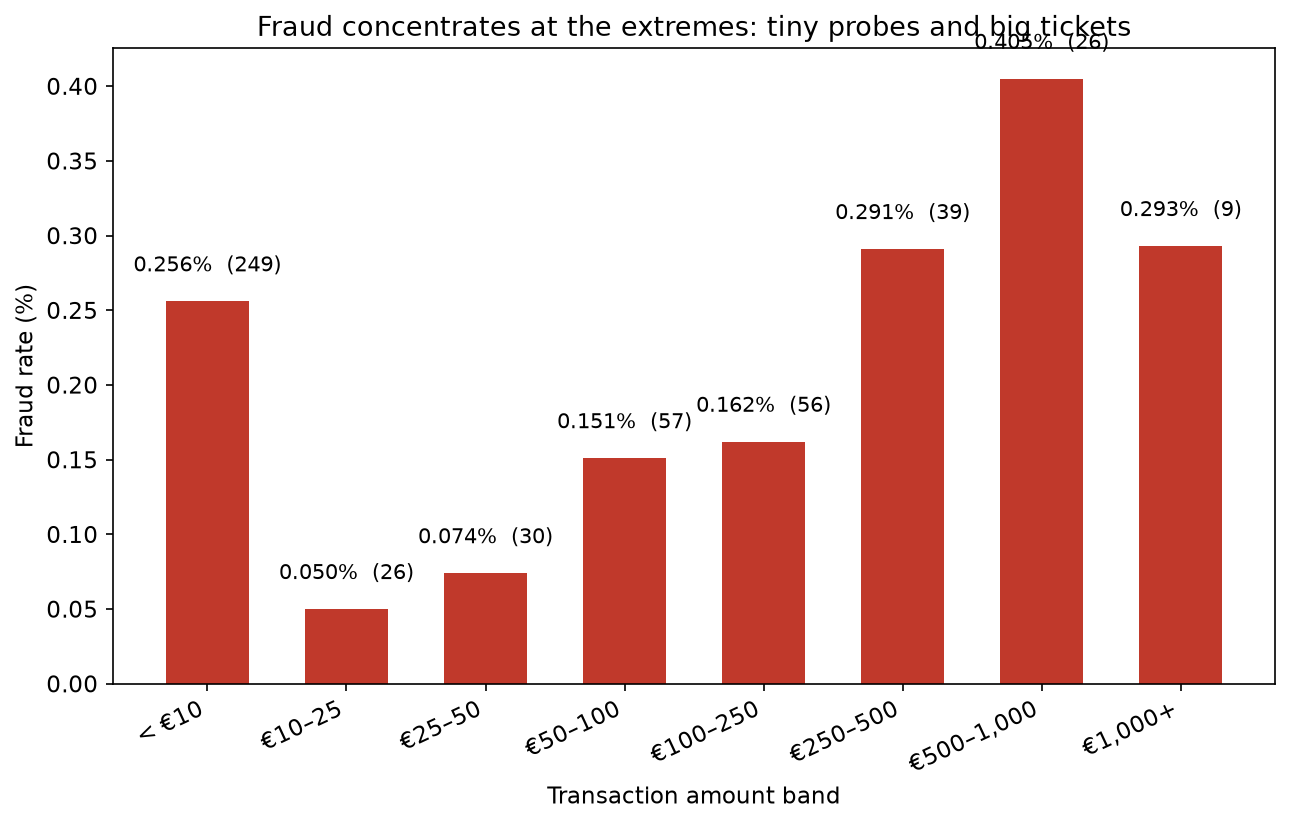

In [ ]:
# see notebooks/build_notebook.py — chart: fraud_rate_by_amount_band
from IPython.display import Image
Image('images/fraud_rate_by_amount_band.png')

## 2. Fraud is a night-time problem

Fraud rate 00–05 is 0.518% vs 0.12–0.17% in the daytime; hour 02 alone hits 1.71%. Hours are relative to the first transaction in the file, not clock time — see notes/cleaning_notes.md.

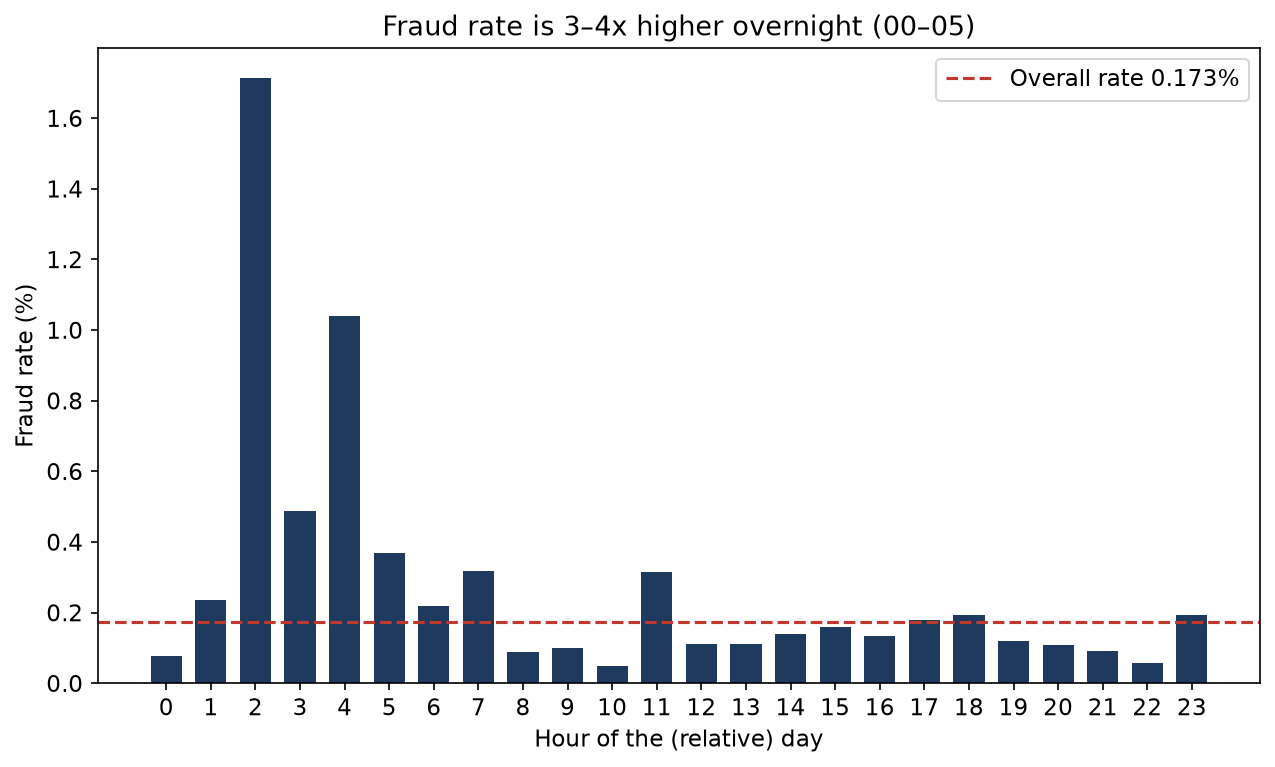

In [ ]:
Image('images/fraud_rate_by_hour.png')

## 3. Fraud is small — median €9.25 vs €22.00

The amount distributions overlap heavily, which is why amount alone cannot be the detector; the V-features have to do the work.

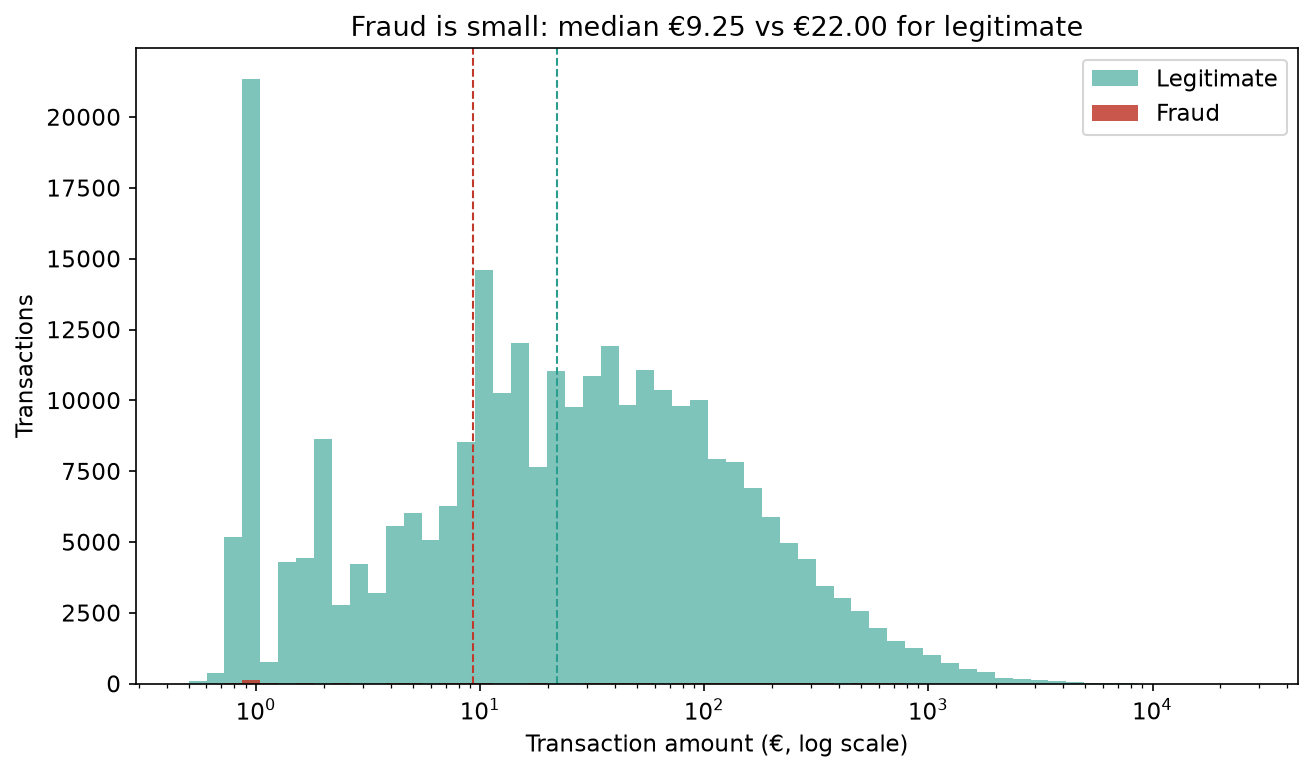

In [ ]:
Image('images/amount_distribution.png')

## 4. Models — time-based split, threshold tuned on training data only

Logistic regression and random forest, both class-weighted, features V1–V28 + log(Amount) + hour. The alert threshold maximises F1 on 3-fold out-of-fold predictions from day 1, then is applied untouched to day 2.

In [ ]:
# see notebooks/build_notebook.py for the full training code
# and notebooks/model_results.txt for the numbers

## 5. Precision–recall: the honest picture at 0.17% fraud

ROC-AUC flatters at this imbalance; average precision is the metric that matters. Both models beat the 0.0015 chance baseline by ~500x.

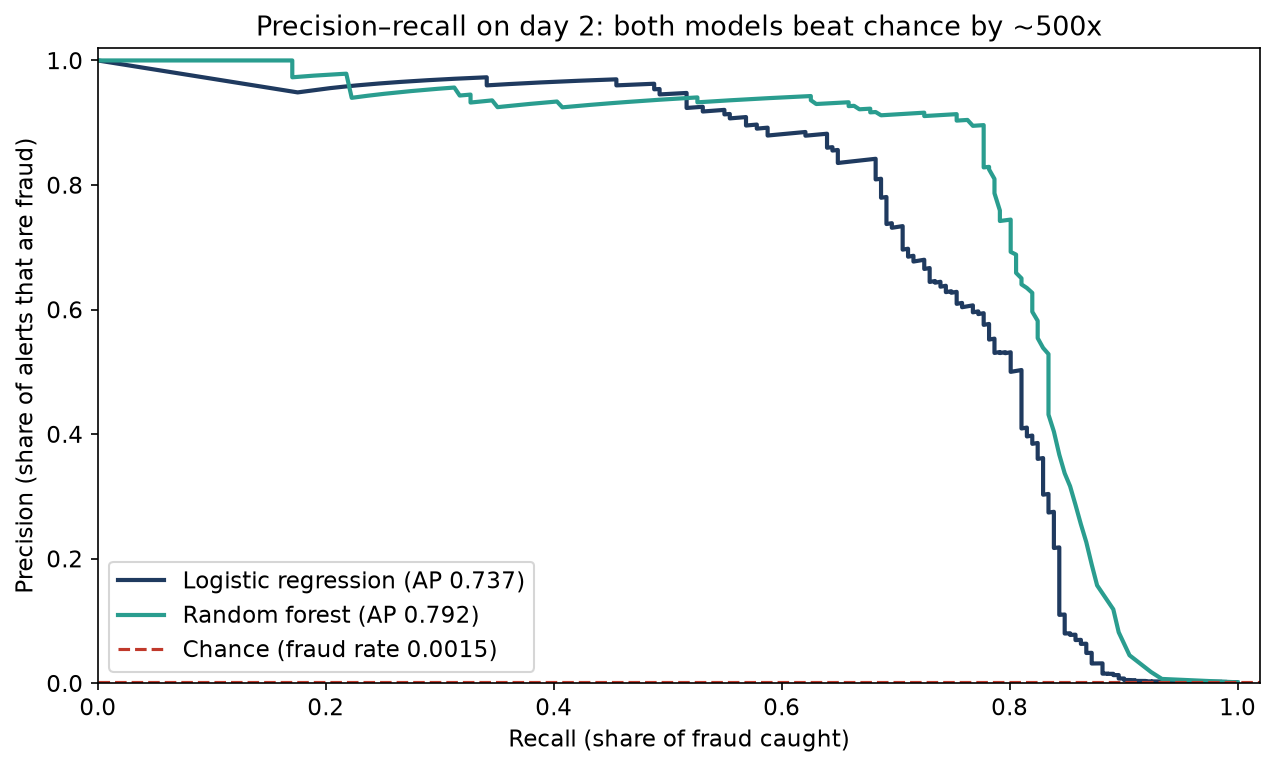

In [ ]:
Image('images/precision_recall_curve.png')

## 6. What the trade-off costs in euros

A missed fraud costs its full amount; a false alert costs EUR 15 of analyst time (assumption). See `dashboard/05_cost_model.csv`.

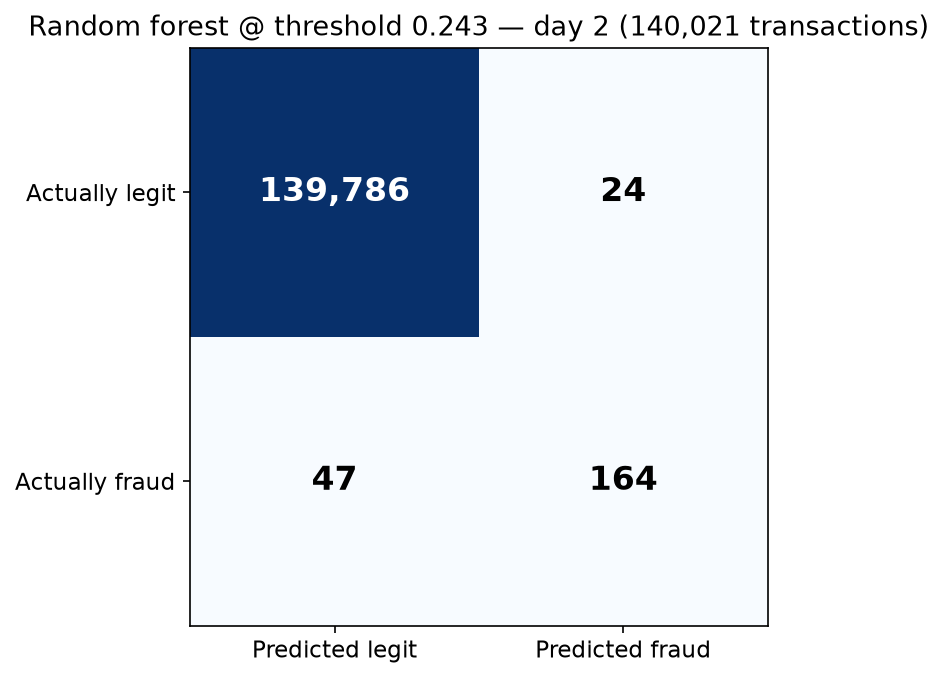

In [ ]:
Image('images/confusion_matrix_rf.png')

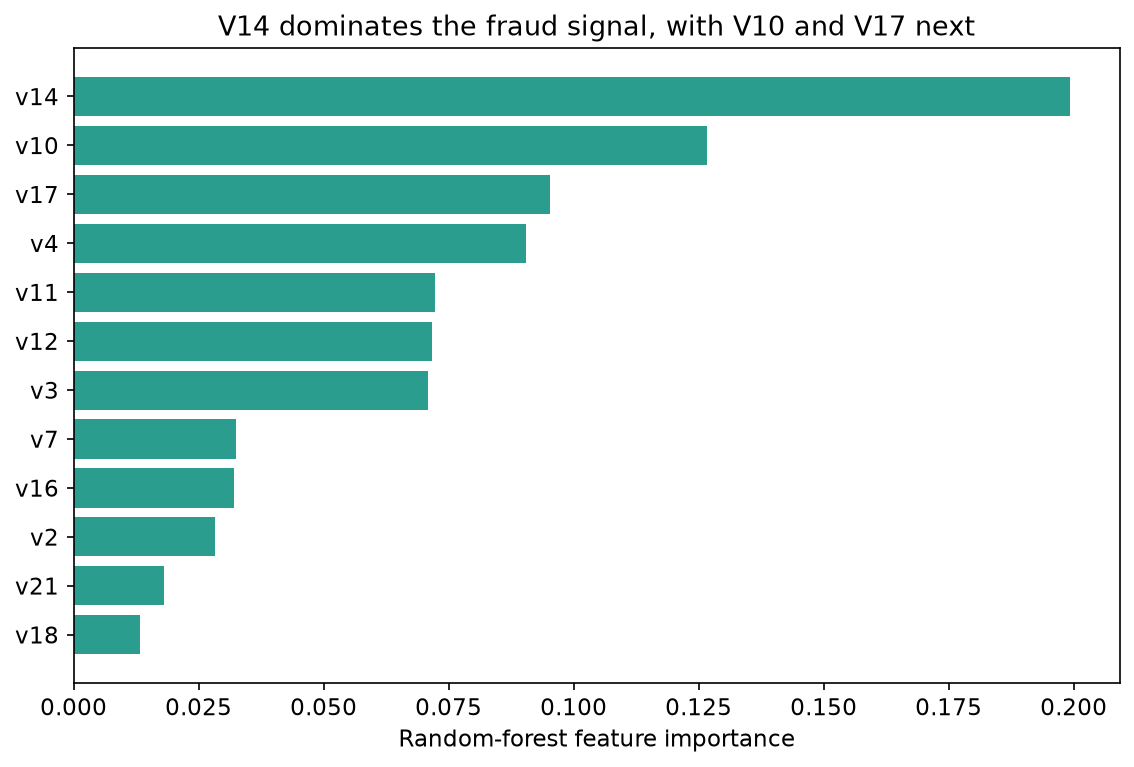

In [ ]:
Image('images/feature_importance.png')